<a href="https://colab.research.google.com/github/PYFTS/notebooks/blob/master/Partitioners.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploring the Universe of Discourse Partitioners

## Environment Setup

### Library install/update

In [1]:
!pip3 install -U git+https://github.com/PYFTS/pyFTS

  Cloning https://github.com/PYFTS/pyFTS to /tmp/pip-req-build-ra_8l_27
  Running command git clone --filter=blob:none --quiet https://github.com/PYFTS/pyFTS /tmp/pip-req-build-ra_8l_27
  Resolved https://github.com/PYFTS/pyFTS to commit 4e0ee7cdd9fc9a8ac9170c0c3496536ef0378cb7
  Preparing metadata (setup.py) ... done
  Created wheel for pyFTS: filename=pyFTS-1.7-py3-none-any.whl size=219429 sha256=d8b8f384ffd37129b6f99da23eb4fb8dd72a2e9d07018958e98d8651c772a24a
  Stored in directory: /tmp/pip-ephem-wheel-cache-l_lt3oad/wheels/3f/88/d0/b42bbeda9160113cbb04e525e61c43fbbda50d31d964fe31ef
Successfully built pyFTS


### External libraries import

In [2]:
import warnings
warnings.filterwarnings('ignore')


import matplotlib.pylab as plt
import pandas as pd
import datetime as _dt

# Monkey patch cho pyFTS cũ
pd.datetime = _dt.datetime


%pylab inline


Populating the interactive namespace from numpy and matplotlib


### Common pyFTS imports 

In [3]:
from pyFTS.partitioners import CMeans, Grid, FCM, Huarng, Entropy, Util as pUtil
from pyFTS.common import Membership as mf
from pyFTS.benchmarks import benchmarks as bchmk
from pyFTS.data import Enrollments

2026-01-21 13:50:30.763776: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769003430.966100      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769003431.022642      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769003431.481615      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769003431.481660      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769003431.481665      17 computation_placer.cc:177] computation placer alr

### Common data transformations

In [4]:
from pyFTS.common import Transformations

tdiff = Transformations.Differential(1)

## Dataset

### Data Loading

In [5]:
from pyFTS.data import TAIEX

dataset = TAIEX.get_data()
dataset_diff = tdiff.apply(dataset)

### Visualization

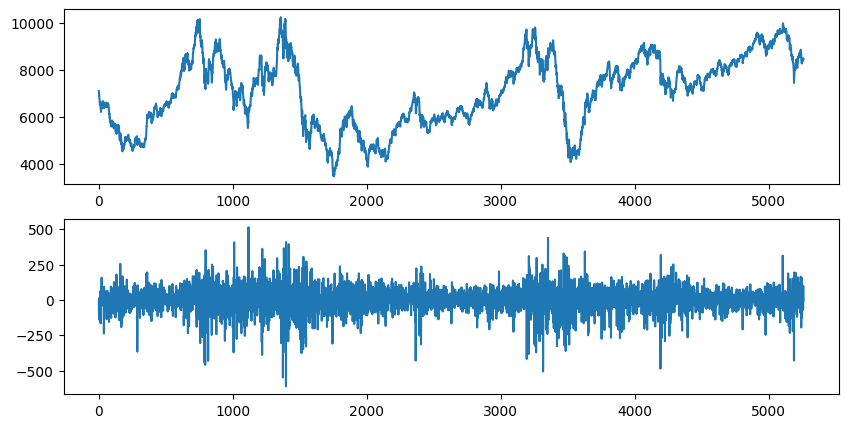

In [6]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=[10,5])
ax[0].plot(dataset)
ax[1].plot(dataset_diff)

## Exploring partitioning schemes

### Same mathod with different membership functions

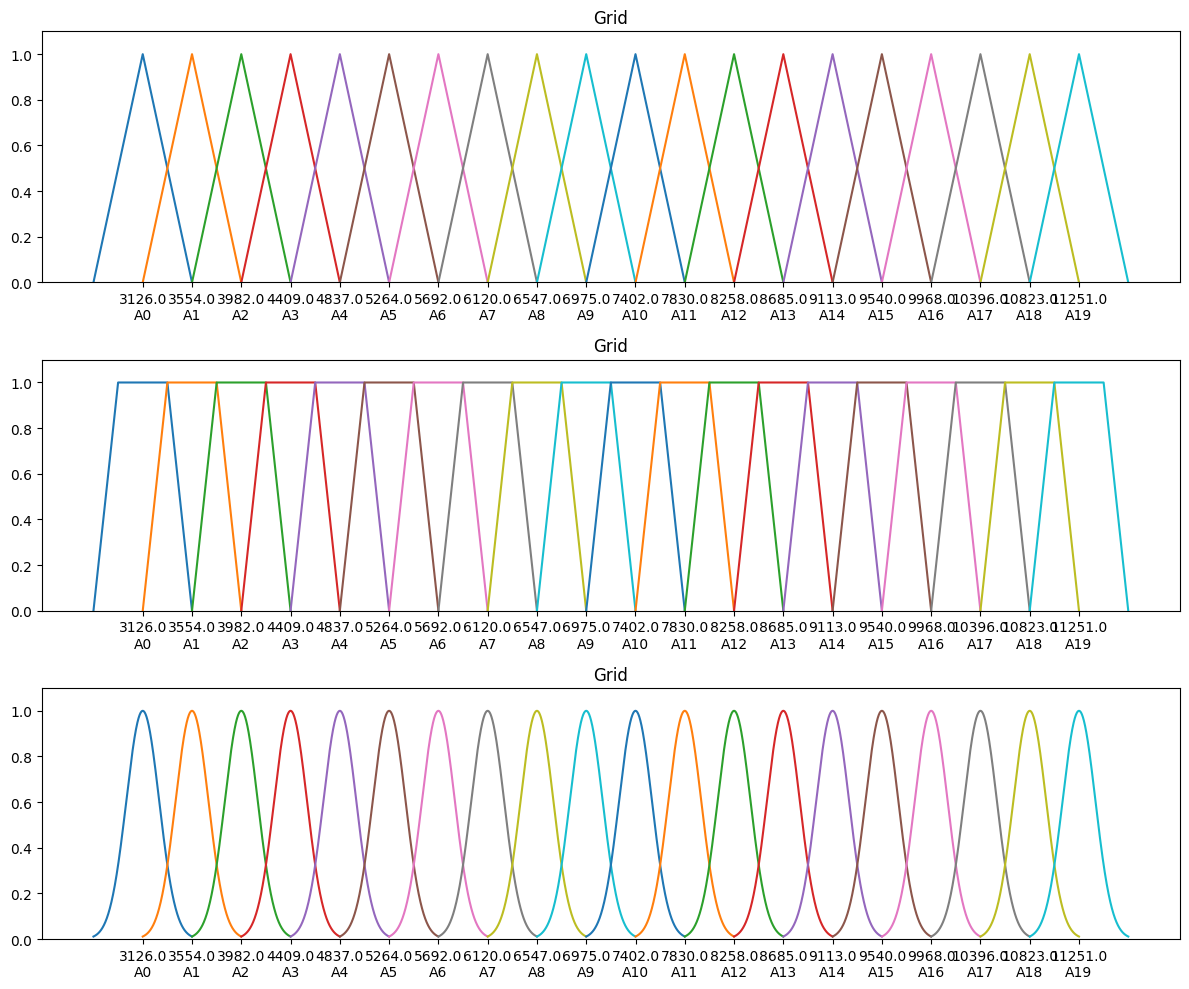

In [7]:
from pyFTS.partitioners import Grid
from pyFTS.common import Membership as mf
from pyFTS.partitioners import Util as pUtil
import matplotlib.pyplot as plt


part = [
    Grid.GridPartitioner(data=dataset, npart=20, func=mf.trimf),
    Grid.GridPartitioner(data=dataset, npart=20, func=mf.trapmf),
    Grid.GridPartitioner(data=dataset, npart=20, func=mf.gaussmf),
]

sets   = [p.sets for p in part]
titles = [p.name for p in part]

pUtil.plot_sets(dataset, sets, titles)
plt.show()


In [8]:
for p in part:
    print(p)

Grid:
A0: trimf([np.float64(2698.8404736842103), np.float64(3126.4335), np.float64(3554.02652631579)])
A1: trimf([np.float64(3126.4335), np.float64(3554.02652631579), np.float64(3981.6195526315796)])
A2: trimf([np.float64(3554.02652631579), np.float64(3981.619552631579), np.float64(4409.2125789473685)])
A3: trimf([np.float64(3981.6195526315787), np.float64(4409.2125789473685), np.float64(4836.805605263158)])
A4: trimf([np.float64(4409.2125789473685), np.float64(4836.805605263158), np.float64(5264.398631578948)])
A5: trimf([np.float64(4836.805605263158), np.float64(5264.398631578948), np.float64(5691.991657894738)])
A6: trimf([np.float64(5264.398631578948), np.float64(5691.991657894738), np.float64(6119.5846842105275)])
A7: trimf([np.float64(5691.991657894737), np.float64(6119.584684210527), np.float64(6547.177710526316)])
A8: trimf([np.float64(6119.584684210527), np.float64(6547.177710526316), np.float64(6974.770736842106)])
A9: trimf([np.float64(6547.177710526316), np.float64(6974.770

### Same mathod with different membership functions and transformation

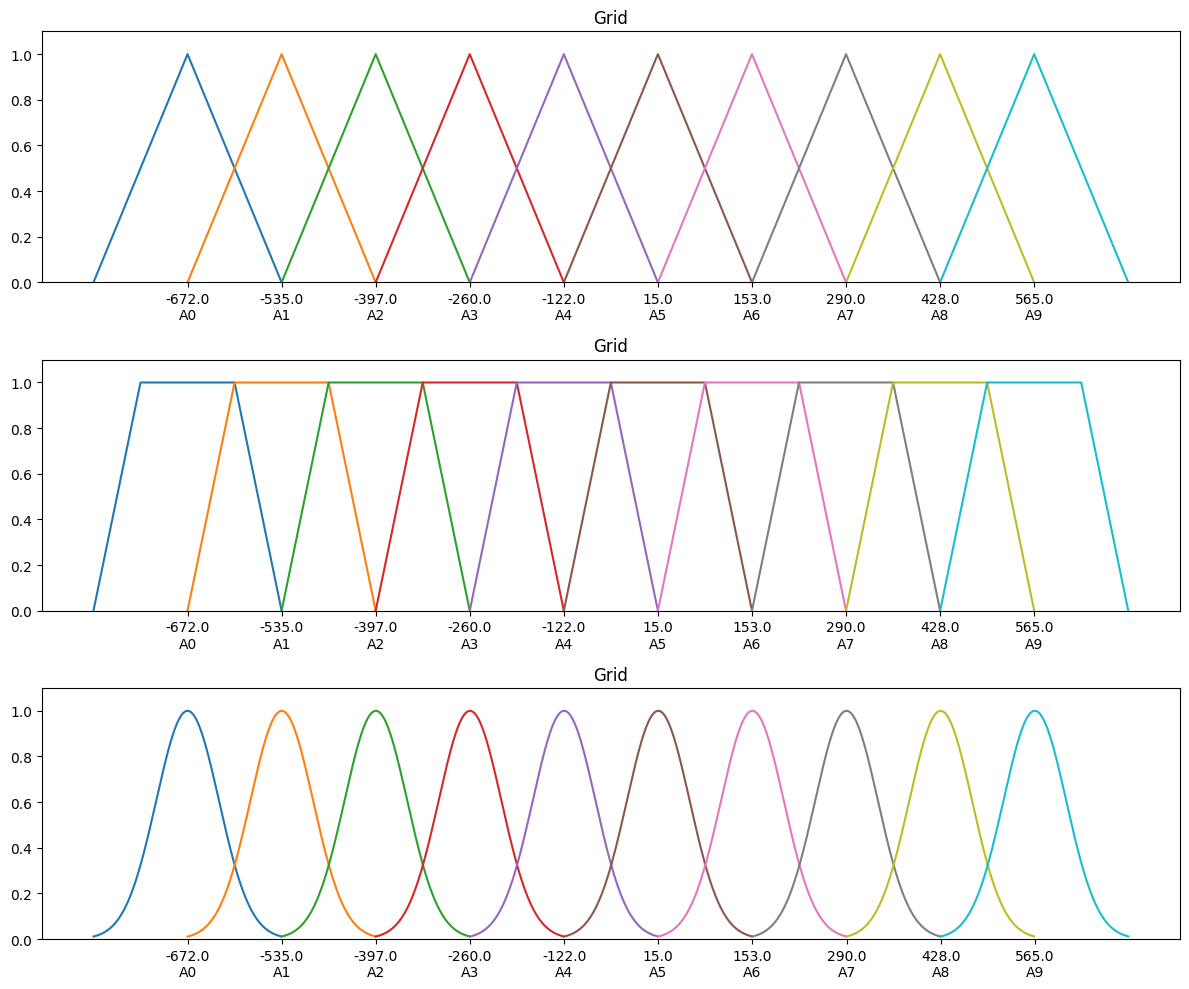

In [9]:
parts = [
    Grid.GridPartitioner(data=dataset, npart=10, func=mf.trimf, transformation=tdiff),
    Grid.GridPartitioner(data=dataset, npart=10, func=mf.trapmf, transformation=tdiff),
    Grid.GridPartitioner(data=dataset, npart=10, func=mf.gaussmf, transformation=tdiff),
]

sets   = [p.sets for p in parts]
titles = [p.name for p in parts]

pUtil.plot_sets(dataset, sets, titles)
plt.show()

In [10]:
for p in part:
    print(p)

Grid:
A0: trimf([np.float64(2698.8404736842103), np.float64(3126.4335), np.float64(3554.02652631579)])
A1: trimf([np.float64(3126.4335), np.float64(3554.02652631579), np.float64(3981.6195526315796)])
A2: trimf([np.float64(3554.02652631579), np.float64(3981.619552631579), np.float64(4409.2125789473685)])
A3: trimf([np.float64(3981.6195526315787), np.float64(4409.2125789473685), np.float64(4836.805605263158)])
A4: trimf([np.float64(4409.2125789473685), np.float64(4836.805605263158), np.float64(5264.398631578948)])
A5: trimf([np.float64(4836.805605263158), np.float64(5264.398631578948), np.float64(5691.991657894738)])
A6: trimf([np.float64(5264.398631578948), np.float64(5691.991657894738), np.float64(6119.5846842105275)])
A7: trimf([np.float64(5691.991657894737), np.float64(6119.584684210527), np.float64(6547.177710526316)])
A8: trimf([np.float64(6119.584684210527), np.float64(6547.177710526316), np.float64(6974.770736842106)])
A9: trimf([np.float64(6547.177710526316), np.float64(6974.770

### Several different mathods

Một số partitioner dựa trên fuzzy clustering trong pyFTS (ví dụ FCM) không tương thích hoàn toàn với môi trường Python mới và có thể gây lỗi chỉ số. Do đó, các partitioner ổn định hơn như Grid, CMeans, Entropy và Huarng được sử dụng để so sánh.

**Huarng.HuarngPartitioner** bùng nổ luật -> khó kiểm soát nên ko thực nghiệm lại

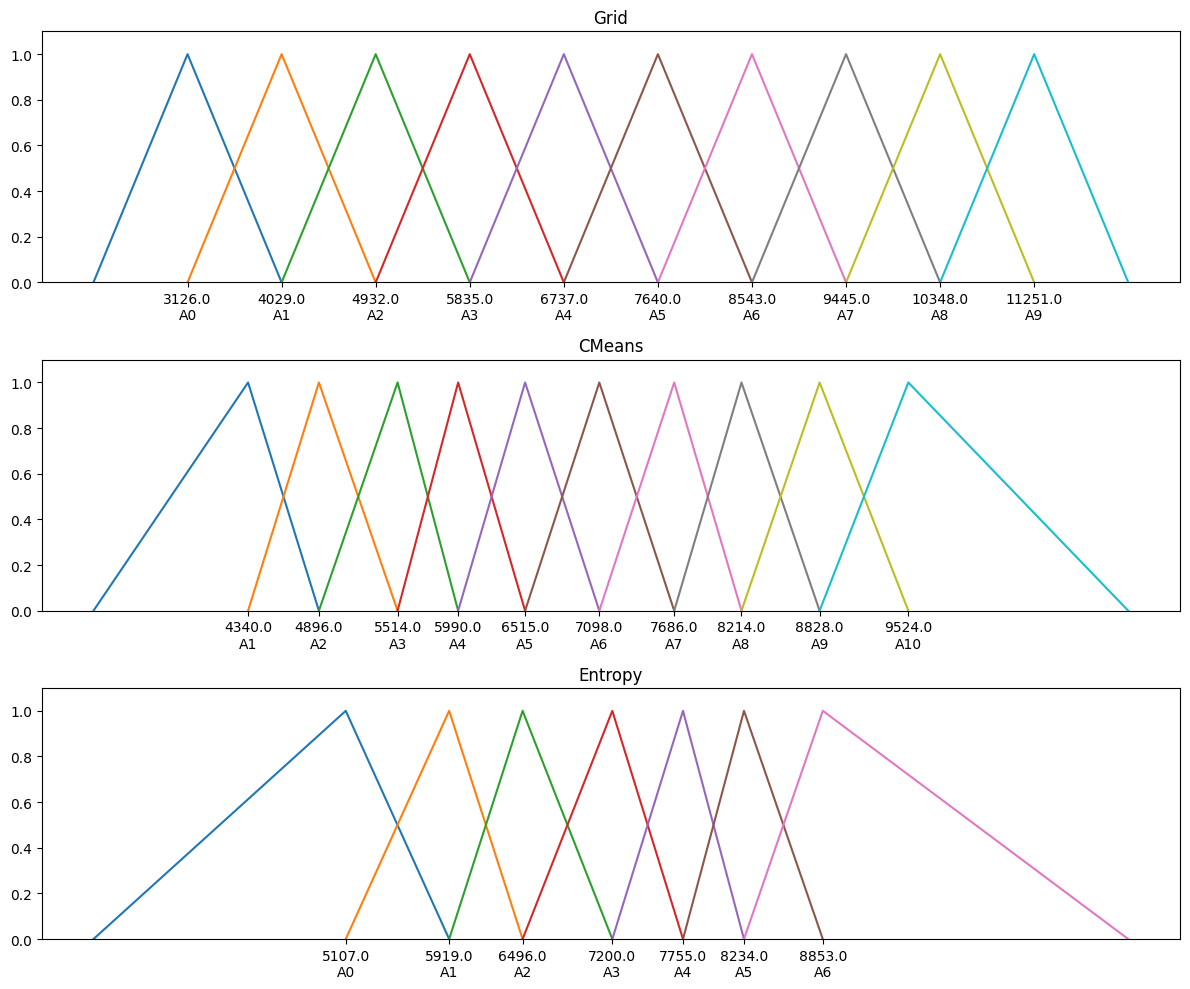

In [11]:
from pyFTS.partitioners import Grid
from pyFTS.common import Membership as mf
from pyFTS.partitioners import Util as pUtil
import matplotlib.pyplot as plt


partitioners = [
    Grid.GridPartitioner(data=dataset, npart=10, func=mf.trimf),
    CMeans.CMeansPartitioner(data=dataset, npart=10, func=mf.trimf),
    Entropy.EntropyPartitioner(data=dataset, npart=10, func=mf.trimf),
]

sets   = [p.sets for p in partitioners]
titles = [p.name for p in partitioners]

pUtil.plot_sets(dataset, sets, titles)
plt.show()


In [12]:
for p in partitioners:
    print(p)

Grid:
A0: trimf([np.float64(2223.737111111111), np.float64(3126.4335), np.float64(4029.129888888889)])
A1: trimf([np.float64(3126.4335), np.float64(4029.129888888889), np.float64(4931.826277777778)])
A2: trimf([np.float64(4029.129888888889), np.float64(4931.826277777778), np.float64(5834.522666666668)])
A3: trimf([np.float64(4931.826277777778), np.float64(5834.522666666668), np.float64(6737.219055555557)])
A4: trimf([np.float64(5834.522666666668), np.float64(6737.219055555556), np.float64(7639.915444444445)])
A5: trimf([np.float64(6737.219055555557), np.float64(7639.915444444446), np.float64(8542.611833333334)])
A6: trimf([np.float64(7639.915444444445), np.float64(8542.611833333334), np.float64(9445.308222222224)])
A7: trimf([np.float64(8542.611833333332), np.float64(9445.308222222222), np.float64(10348.004611111111)])
A8: trimf([np.float64(9445.308222222222), np.float64(10348.004611111111), np.float64(11250.701000000001)])
A9: trimf([np.float64(10348.004611111111), np.float64(11250.70